# `two_point_correlation`

The two-point correlation function $S_2(r)$ describes the probability that two points separated by a distance $r$ both lie in the phase of interest. At each displacement, the FFT counts pairs whose endpoints both lie in the selected phase. The function divides by the number of pairs contained within the image at that displacement, then averages the fractions in each distance bin with equal weight per displacement.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import porespy as ps

ps.visualization.set_mpl_style()

## `im`

The input is a binary image with `True` (1) in the phase of interest and `False` (0) elsewhere. Here, the phase of interest is the void space.

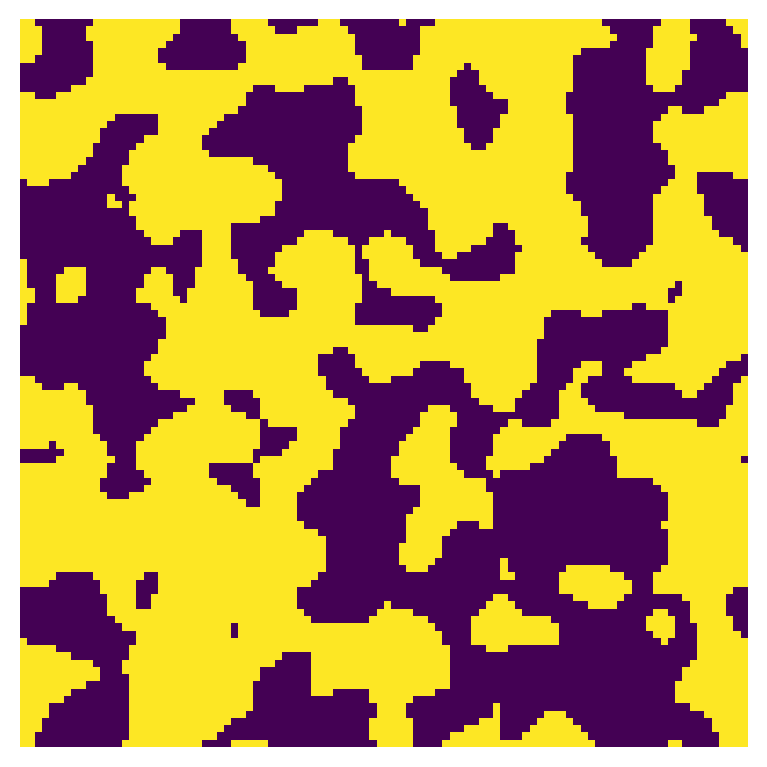

In [5]:
np.random.seed(10)
im = ps.generators.blobs(shape=[100, 100, 100])

fig, ax = plt.subplots(1, 1, figsize=[4, 4])
ax.imshow(im[:, :, 6], origin="lower", interpolation="none")
ax.axis(False);

## Interpreting the result

The example plots `probability_scaled`, which gives $S_2(r)$. The `probability` field gives $S_2(r)/\phi$, where $\phi$ is the phase fraction. The first bin in this example spans $[0, 1)$ voxels and contains only zero lag, so its value is $S_2(0)=\phi$ even though it is plotted at the bin center of 0.5 voxels. At separations where the two phase indicators are effectively independent, $S_2(r)$ approaches $\phi^2$.

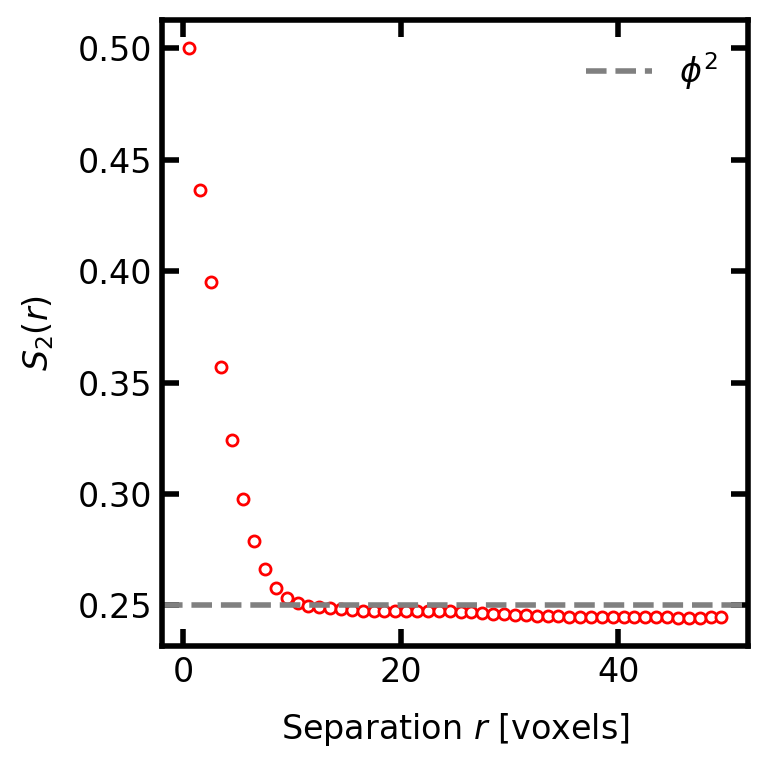

In [7]:
data = ps.metrics.two_point_correlation(im)
phi = im.mean()

fig, ax = plt.subplots(1, 1, figsize=[4, 4])
ax.plot(data.distance, data.probability_scaled, "r.")
ax.axhline(phi**2, color="0.5", linestyle="--", label=r"$\phi^2$")
ax.set_xlabel(r"Separation $r$ [voxels]")
ax.set_ylabel(r"$S_2(r)$")
ax.legend();

## GPU execution

With CuPy installed on a CUDA system, use the same function to compute the correlation on the GPU.

```python
data = ps.metrics.two_point_correlation(im, backend="cupy")
```

Passing a CuPy array as `im` selects the GPU automatically. The result fields are NumPy arrays, so the same plotting code works with either backend.